# NPC DSC 2026: Exploratory Data Analysis

This notebook comes **before** preprocessing. It looks only at the original 48 kHz stereo FLAC files, so every preprocessing choice in `02_preprocessing.ipynb` can be traced back to evidence here.

The questions we want answered:

1. **What do we have?** Classes, recording groups, durations.
2. **Is the audio clean?** Levels, clipping, DC offset.
3. **Where do the birds sing?** Frequency ranges per species. Is there anything above 16 kHz?
4. **What does the background sound like?** Can background alone give away the species?
5. **Does test look like train?** Distribution shift, and hints of `Unknown` species.
6. **Look and listen.** Spectrograms and audio for each class and for test.

The heavy computation is in `scripts/00_eda_features.py` (about 1 minute). The cells below only analyse its outputs.

In [1]:
import subprocess, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
PIPELINE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"src").is_dir()), Path.cwd())
assert (PIPELINE / "src").exists(), "run from inside the DSC_Pipeline tree"
sys.path.insert(0, str(PIPELINE))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf, librosa
from IPython.display import Audio, display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE

from src import config as C

CLASSES = C.CLASSES
CLASS_COLOR = {"Bondol Jawa": "#2a78d6", "Cendrawasih": "#eb6834", "Kutilang": "#1baf7a", "test": "#8c8b85"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
pd.set_option("display.width", 160)

def run(script, *args):
    _STAGE = {
    "00_eda_features.py":"stages/01_eda","01_extract_features.py":"stages/01_eda",
    "02_analyze.py":"stages/01_eda","03_plots.py":"stages/01_eda","04_report.py":"stages/01_eda",
    "01_inventory.py":"stages/02_preprocessing","02_cache_audio.py":"stages/02_preprocessing",
    "03_make_folds.py":"stages/02_preprocessing","04_activity_and_noise.py":"stages/02_preprocessing",
    "05_compare_frontends.py":"stages/02_preprocessing",
    "06_train.py":"stages/03_modeling","07_tune_unknown.py":"stages/03_modeling","08_infer.py":"stages/03_modeling",
}
    cmd = [sys.executable, script, *map(str, args)]
    print("$", " ".join(cmd[1:]), flush=True)
    p = subprocess.Popen(cmd, cwd=PIPELINE / _STAGE.get(script, "stages"), stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"{script} failed")

def model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))

In [2]:
EDA = C.OUT_DIR / "eda"
if not (EDA / "clip_stats.csv").exists():
    run("00_eda_features.py")
st = pd.read_csv(EDA / "clip_stats.csv")
sp = np.load(EDA / "spectra.npz"); FREQ = sp["freqs"]
MEL = np.load(EDA / "mel_summary.npy")
st["who"] = st.label.fillna("test")
TR = (st.split == "train").values
print(f"{TR.sum()} train clips, {(~TR).sum()} test clips")

1826 train clips, 814 test clips


## 1. What do we have?

,clips,groups,share,clips_per_group
label,,,,
Bondol Jawa,1124,7,0.616,161.0
Cendrawasih,83,4,0.045,21.0
Kutilang,619,4,0.339,155.0


15 source groups; groups containing more than one species: 0


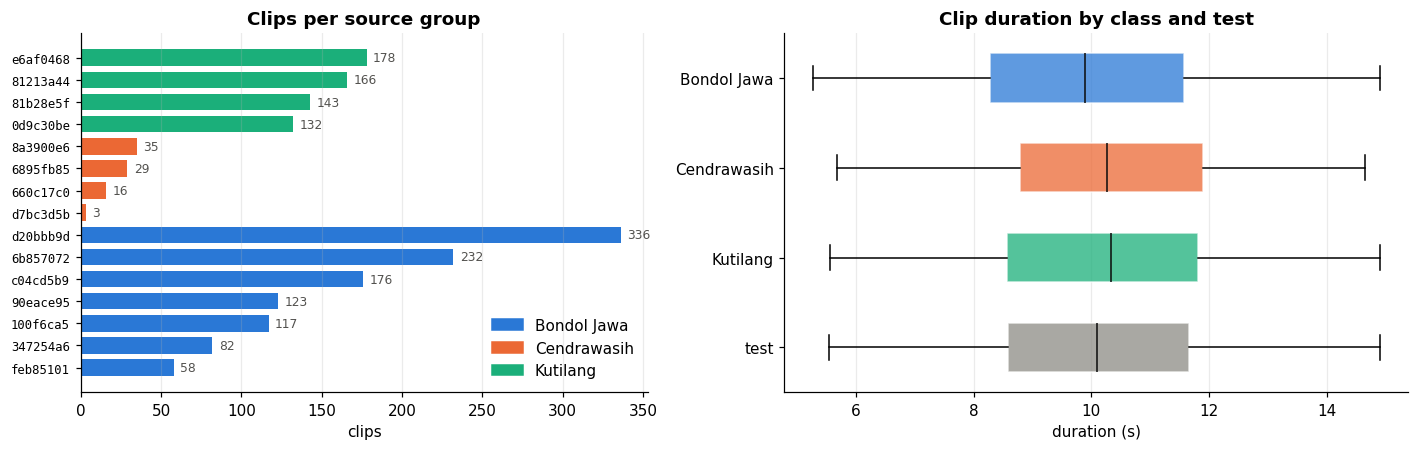

median duration per group ranges from 6.3 to 11.3 s


In [3]:
tr = st[TR]
summary = tr.groupby("label").agg(clips=("file_id", "size"), groups=("source_group", "nunique"))
summary["share"] = (summary.clips / summary.clips.sum()).round(3)
summary["clips_per_group"] = (summary.clips / summary.groups).round(0)
display(summary)
groups = tr.groupby(["source_group", "label"]).size().rename("clips").reset_index().sort_values(["label", "clips"])
print(f"{len(groups)} source groups; groups containing more than one species: "
      f"{(groups.groupby('source_group').label.nunique() > 1).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.barh(range(len(groups)), groups.clips, color=groups.label.map(CLASS_COLOR), height=0.75)
ax.set_yticks(range(len(groups)), [g[:8] for g in groups.source_group], fontsize=8, family="monospace")
for i, n in enumerate(groups.clips):
    ax.text(n + 4, i, str(n), va="center", fontsize=8, color="#52514e")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[c]) for c in CLASSES], labels=CLASSES,
          loc="lower right", frameon=False)
ax.set_xlabel("clips"); ax.set_title("Clips per source group"); ax.grid(axis="y", visible=False)

ax = axes[1]
order = CLASSES + ["test"]
data = [st.loc[st.who == w, "duration"].values for w in order]
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color="#0b0b0b"))
for patch, w in zip(bp["boxes"], order):
    patch.set_facecolor(CLASS_COLOR[w]); patch.set_alpha(0.75); patch.set_edgecolor("white")
ax.set_yticks(range(1, len(order) + 1), order); ax.invert_yaxis()
ax.set_xlabel("duration (s)"); ax.set_title("Clip duration by class and test"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

dur_g = tr.groupby("source_group").duration.median()
print(f"median duration per group ranges from {dur_g.min():.1f} to {dur_g.max():.1f} s")

**Findings.**
- 15 source groups, and **each one contains a single species**. A species is therefore represented by only a handful of independent recordings: 7 for Bondol Jawa, 4 each for Kutilang and Cendrawasih.
- Imbalance: Bondol Jawa makes up 62% of the clips and Cendrawasih 4.5%, with one Cendrawasih group of only 3 clips.
- Duration is about 5–15 s for every class and for test, so duration doesn't give away the class.

**Implication.** Validation has to hold out whole groups, and the class imbalance needs handling (weights or a balanced sampler).

## 2. Is the audio clean?

In [4]:
q = st.groupby("who").agg(clips=("file_id", "size"),
                          rms_db_median=("rms_db", "median"), rms_db_sd=("rms_db", "std"),
                          peak_max=("peak", "max"), clipped_clips=("clip_frac", lambda s: int((s > 0).sum())),
                          dc_offset_max=("dc_offset", lambda s: float(np.abs(s).max())),
                          snr_est_db_median=("snr_est_db", "median")).loc[order]
display(q.round(3))
capped = st.groupby("who").peak.apply(lambda s: (s.round(3) == 0.98).mean()).loc[order]
print("share of clips whose peak is exactly 0.98:", capped.round(2).to_dict())

,clips,rms_db_median,rms_db_sd,peak_max,clipped_clips,dc_offset_max,snr_est_db_median
who,,,,,,,
Bondol Jawa,1124,-21.341,2.955,0.98,0,0.037,10.357
Cendrawasih,83,-21.897,3.004,0.98,0,0.026,7.806
Kutilang,619,-21.079,2.839,0.98,0,0.024,10.963
test,814,-21.118,2.782,0.98,0,0.031,10.353


share of clips whose peak is exactly 0.98: {'Bondol Jawa': 0.46, 'Cendrawasih': 0.42, 'Kutilang': 0.37, 'test': 0.43}


**Findings.**
- No clipped samples, and DC offsets are negligible.
- About 43% of clips, in train and in test alike, peak at **exactly 0.98**. No natural recording does that, so the organisers almost certainly applied a peak normaliser or limiter. Because it applies equally to every class and to test, it is not a shortcut.
- Loudness is almost identical across classes and test (median about −21 dBFS, SD about 3 dB). The organisers probably level-normalised the clips, so **loudness is not a shortcut** to the species.
- Cendrawasih has a lower SNR (about 7.8 dB vs about 10–11 dB), so its calls sit closer to the noise. That is one reason it's the hardest class.

**Implication.** No repair step is needed. Per-clip normalisation is still a good idea, but it is not fixing a real level problem.

## 3. Where do the birds sing?

For each clip we take the 95th-percentile power per frequency (the loud events) minus the 10th percentile (the background floor). The difference, which we call **prominence**, shows where sound rises above the background, i.e. where the calls are. The curves are medians over clips.

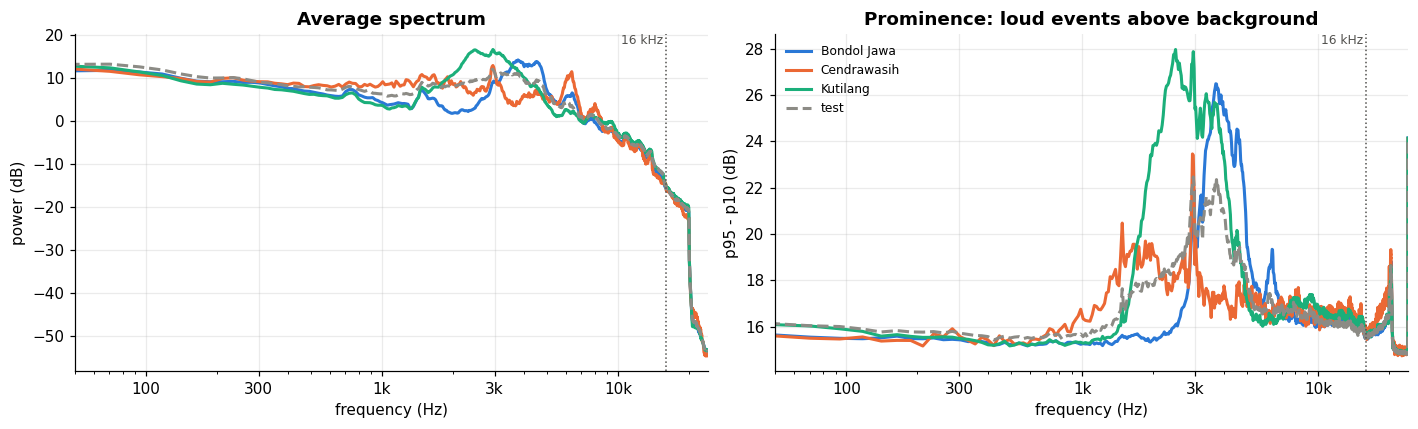

,0k_0.5k %,0.5k_2k %,2k_8k %,8k_16k %,16k_24k %
who,,,,,
Bondol Jawa,7.7,5.5,74.8,2.8,0.1
Cendrawasih,9.4,17.4,53.7,2.9,0.0
Kutilang,6.5,6.9,74.0,3.1,0.1
test,8.3,10.4,65.6,3.2,0.1


In [5]:
prom = sp["p95"] - sp["floor"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for w in order:
    m = (st.who == w).values
    ls = "--" if w == "test" else "-"
    axes[0].plot(FREQ[1:], np.median(sp["mean"][m], 0)[1:], color=CLASS_COLOR[w], lw=2, ls=ls, label=w)
    axes[1].plot(FREQ[1:], np.median(prom[m], 0)[1:], color=CLASS_COLOR[w], lw=2, ls=ls, label=w)
for ax, title, yl in [(axes[0], "Average spectrum", "power (dB)"),
                      (axes[1], "Prominence: loud events above background", "p95 - p10 (dB)")]:
    ax.set_xscale("log"); ax.set_xlim(50, 24000)
    ax.axvline(16000, color="#52514e", lw=1, ls=":")
    ax.text(15500, ax.get_ylim()[1], "16 kHz", ha="right", va="top", fontsize=8, color="#52514e")
    ax.set_xticks([100, 300, 1000, 3000, 10000], ["100", "300", "1k", "3k", "10k"])
    ax.set_xlabel("frequency (Hz)"); ax.set_ylabel(yl); ax.set_title(title)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

bands = [c for c in st.columns if c.startswith("band_")]
(st.groupby("who")[bands].median().loc[order] * 100).round(1).rename(columns=lambda c: c.replace("band_", "") + " %")

**Findings.**
- **Above 16 kHz there is essentially nothing** (about 0.1% of the energy for every class). Resampling to 32 kHz, which keeps everything up to 16 kHz, loses no bird information.
- Bondol Jawa and Kutilang are concentrated in **2–8 kHz** (about 74–75% of their energy).
- **Cendrawasih is lower-pitched**: about 17% of its energy is in 0.5–2 kHz, against 5–7% for the other two classes.
- Test sits in between (about 10% in 0.5–2 kHz). That fits test having more low-pitched calls, from more Cendrawasih or from Unknown species.

**Implication.** Keep `fmax` at 15–16 kHz and keep a low `fmin` (40 Hz). **Do not add a high-pass filter above roughly 300 Hz**, because it would cut into Cendrawasih and possibly Unknown species.

## 4. What does the background sound like?

The 10th-percentile spectrum of each clip is its **background floor**: the sound that is always there (insects, hum, wind, room tone). Each line below is one source group.

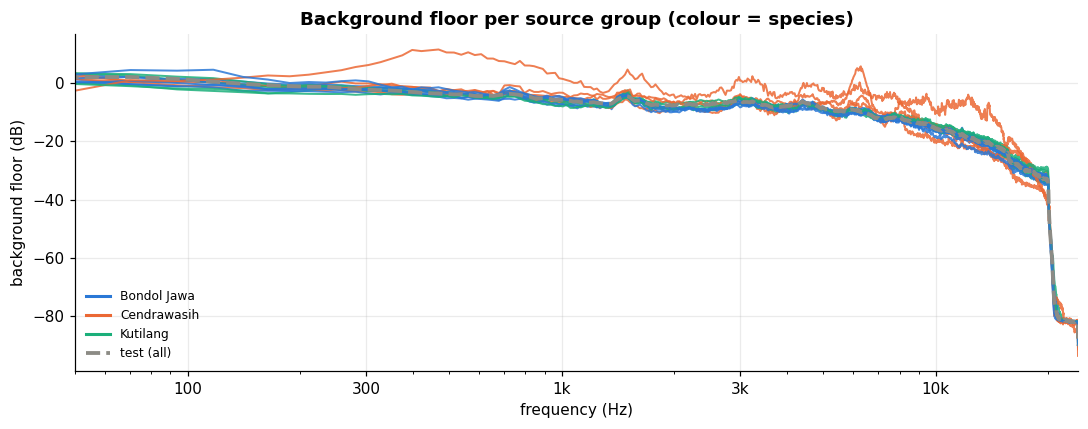

Species predicted from the background floor ALONE: balanced accuracy 0.52 (chance 0.33)
Source group predicted from the background floor alone: balanced accuracy 0.17 (chance 0.07)


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for (grp, lab), d in tr.groupby(["source_group", "label"]):
    m = st.source_group.eq(grp).values
    ax.plot(FREQ[1:], np.median(sp["floor"][m], 0)[1:], color=CLASS_COLOR[lab], lw=1.3, alpha=0.85)
ax.plot(FREQ[1:], np.median(sp["floor"][~TR], 0)[1:], color=CLASS_COLOR["test"], lw=2.5, ls="--", label="test (all)")
ax.set_xscale("log"); ax.set_xlim(50, 24000)
ax.set_xticks([100, 300, 1000, 3000, 10000], ["100", "300", "1k", "3k", "10k"])
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("background floor (dB)")
ax.set_title("Background floor per source group (colour = species)")
ax.legend(handles=[plt.Line2D([], [], color=CLASS_COLOR[c], lw=2) for c in CLASSES] +
          [plt.Line2D([], [], color=CLASS_COLOR["test"], lw=2.5, ls="--")], labels=CLASSES + ["test (all)"],
          frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

Fl = sp["floor"][TR][:, ::4]
g, y = tr.source_group.values, tr.label.values
cv = StratifiedKFold(3, shuffle=True, random_state=0)
acc_sp = balanced_accuracy_score(y, cross_val_predict(model(), Fl, y, cv=cv))
acc_gr = balanced_accuracy_score(g, cross_val_predict(model(), Fl, g, cv=cv))
print(f"Species predicted from the background floor ALONE: balanced accuracy {acc_sp:.2f} (chance 0.33)")
print(f"Source group predicted from the background floor alone: balanced accuracy {acc_gr:.2f} (chance {1/15:.2f})")

**Findings.**
- Background floors differ visibly between groups.
- Using **only the background, with no bird call information, a simple model gets about 0.52 balanced accuracy on species** (chance is 0.33). The background carries real species information, but only because each group is one species. This is the shortcut we must not let the model learn.

**Implication.** This is direct evidence for (a) group-held-out validation, (b) PCEN, which suppresses the stationary background, and (c) cross-group background mixing in training.

### 4b. The added noise: is it the same everywhere?

The gallery in section 6 shows a recurring **rhythmic pulse noise** (broadband bursts about once a second with harmonic lines, which sounds like insects) in clips of every species. The task description says recordings contain rain, wind and insects. We measure three noise indicators per clip:
- **pulse strength:** how periodic the 8–16 kHz energy is (autocorrelation at a 0.3–2 s lag). Values above 0.5 mean a strong rhythmic pulse.
- **low-frequency share:** the fraction of energy below 300 Hz (wind and rumble).
- **spectral flatness:** how noise-like (flat) the spectrum is (rain and hiss).

If a noise type were concentrated in one species, it would be a shortcut. If it is spread evenly, it is just a nuisance the model has to learn to ignore.

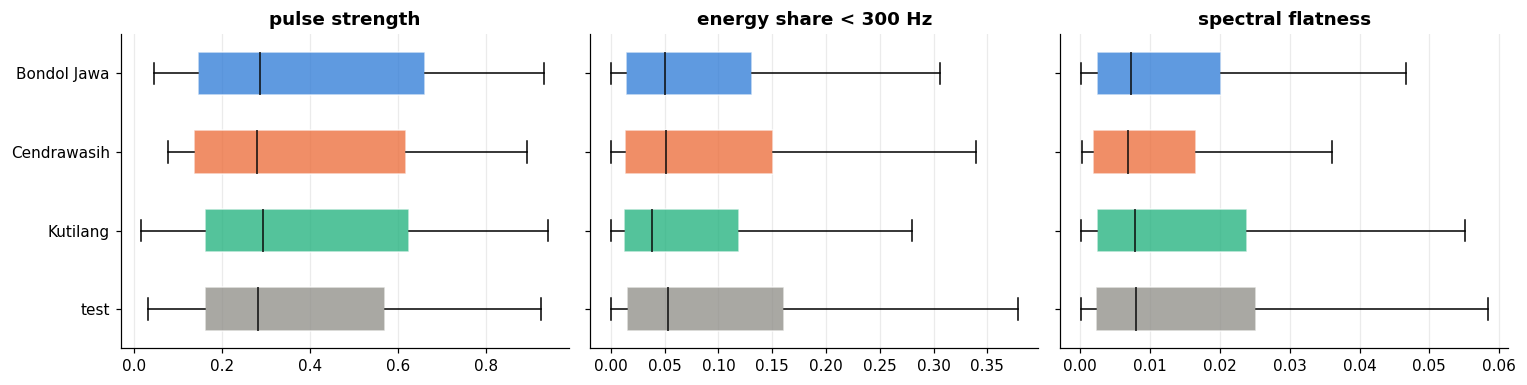

,strong pulse (>0.5),"pulse share, lowest group","pulse share, highest group"
Bondol Jawa,0.35,0.24,0.38
Cendrawasih,0.35,0.28,0.40
Kutilang,0.34,0.31,0.36
test,0.30,NaN,NaN


typical pulse period of strong pulses: 0.80 s (IQR 0.50-1.09 s)


In [7]:
ind = {"pulse_strength": "pulse strength", "low_share_300": "energy share < 300 Hz", "flatness": "spectral flatness"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (col, name) in zip(axes, ind.items()):
    data = [st.loc[st.who == w, col].values for w in order]
    bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color="#0b0b0b"))
    for patch, w in zip(bp["boxes"], order):
        patch.set_facecolor(CLASS_COLOR[w]); patch.set_alpha(0.75); patch.set_edgecolor("white")
    ax.set_yticks(range(1, len(order) + 1), order if ax is axes[0] else [""] * len(order)); ax.invert_yaxis()
    ax.set_title(name); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

share = pd.DataFrame({
    "strong pulse (>0.5)": st.groupby("who").pulse_strength.apply(lambda s: (s > 0.5).mean()),
    "pulse share, lowest group": tr.groupby(["label", "source_group"]).pulse_strength
        .apply(lambda s: (s > 0.5).mean()).groupby("label").min(),
    "pulse share, highest group": tr.groupby(["label", "source_group"]).pulse_strength
        .apply(lambda s: (s > 0.5).mean()).groupby("label").max(),
}).loc[order]
display(share.round(2))
print("typical pulse period of strong pulses: %.2f s (IQR %.2f-%.2f s)" % tuple(
    st.loc[st.pulse_strength > 0.5, "pulse_period_s"].quantile([.5, .25, .75])))

**Findings.**
- **About one clip in three in every class, almost every group, and test has a strong rhythmic pulse noise** (median period about 0.8 s). The rate is close to the same everywhere (24–40% per group, 30% in test), with no species-specific pattern. The organisers almost certainly mixed the same noise sources into every class, and the test set got the same treatment.
- Wind-like low-frequency energy and rain-like flatness are also spread similarly across classes and test.

**Implication.** The *added* noise is not a shortcut. The shortcut risk comes from the original recordings' own backgrounds (section 4). Because test has the same kinds of noise, the model has to cope with pulses, wind and hiss. That supports noise mixing in training. It also means the "noise bank" should include these noise types, and the activity-based crop selection must not mistake insect pulses for bird calls. Both are checked in `02_preprocessing.ipynb`.

## 5. Does test look like train?

Three checks:
- **Adversarial validation:** can a model tell train clips from test clips? An AUC of 0.5 means they look alike. Higher means a shift.
- **Map:** t-SNE of each clip's log-mel summary.
- **Distance to training data:** for each test clip, the average distance to its 5 nearest training clips. We compare it with the same distance for training clips when their **whole group is left out**. Training clips under that condition are as "new" as a known species from an unseen recording can be. Test clips much farther away than that are candidates for new conditions or `Unknown` species.

In [8]:
X = np.hstack([MEL, st[["rms_db", "snr_est_db", "centroid_hz", "flatness", "onset_rate", "duration"]].values])
p = cross_val_predict(model(), X, (~TR).astype(int), cv=StratifiedKFold(5, shuffle=True, random_state=0),
                      method="predict_proba")[:, 1]
auc = roc_auc_score(~TR, p)
print(f"Adversarial validation AUC (train vs test): {auc:.3f}")

Z = StandardScaler().fit(X[TR]).transform(X)
Ztr, gtr = Z[TR], tr.source_group.values
lgo = np.empty(TR.sum())
for grp in np.unique(gtr):
    m = gtr == grp
    lgo[m] = NearestNeighbors(n_neighbors=5).fit(Ztr[~m]).kneighbors(Ztr[m])[0].mean(1)
d_test = NearestNeighbors(n_neighbors=5).fit(Ztr).kneighbors(Z[~TR])[0].mean(1)
thr = np.quantile(lgo, 0.95)
far = (d_test > thr).mean()
print(f"Test clips farther from training data than 95% of leave-group-out training clips: {far:.1%}")

Adversarial validation AUC (train vs test): 0.766
Test clips farther from training data than 95% of leave-group-out training clips: 17.1%


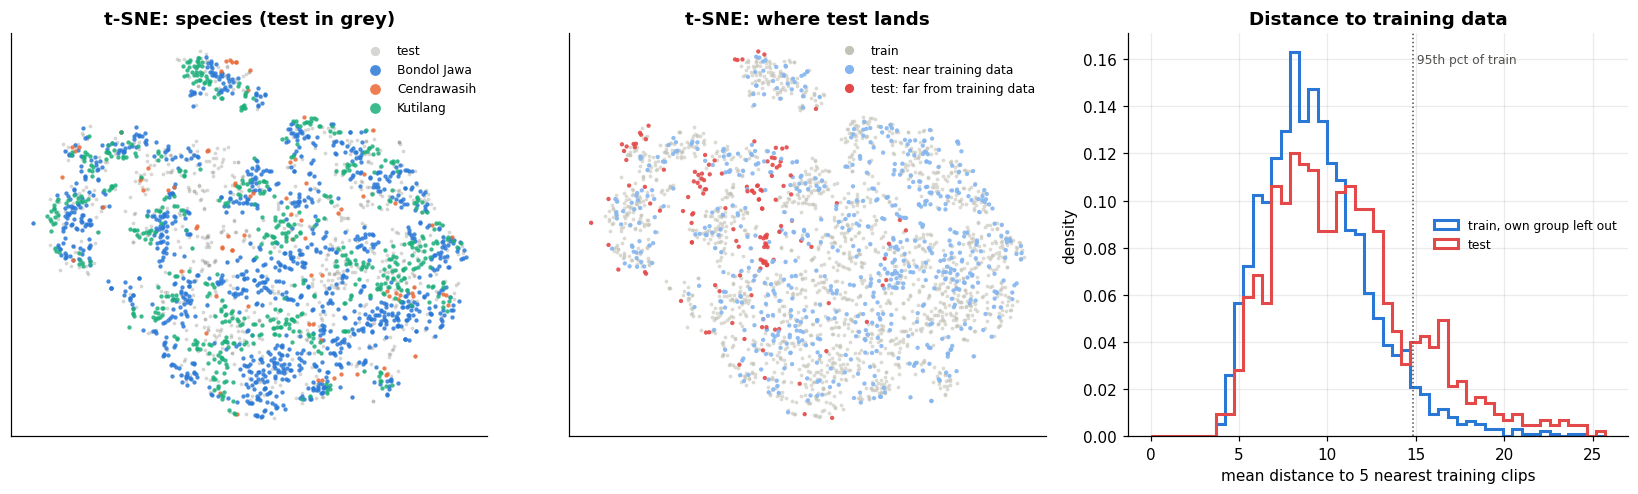

In [9]:
emb = TSNE(n_components=2, perplexity=35, init="pca", random_state=0).fit_transform(Z)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.05]})
ax = axes[0]
ax.scatter(*emb[~TR].T, s=6, color=CLASS_COLOR["test"], alpha=0.35, lw=0, label="test")
for c in CLASSES:
    m = (st.who == c).values
    ax.scatter(*emb[m].T, s=8, color=CLASS_COLOR[c], alpha=0.85, lw=0, label=c)
ax.set_title("t-SNE: species (test in grey)"); ax.legend(frameon=False, fontsize=8, markerscale=2.5)
ax = axes[1]
ax.scatter(*emb[TR].T, s=6, color="#c3c2b7", alpha=0.6, lw=0, label="train")
ax.scatter(*emb[~TR].T, s=8, c=d_test > thr, cmap=plt.matplotlib.colors.ListedColormap(["#86b6ef", "#e34948"]),
           lw=0, alpha=0.9)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, ms=5) for c in ["#c3c2b7", "#86b6ef", "#e34948"]],
          labels=["train", "test: near training data", "test: far from training data"], frameon=False, fontsize=8)
ax.set_title("t-SNE: where test lands")
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax = axes[2]
bins = np.linspace(0, max(np.quantile(d_test, 0.995), np.quantile(lgo, 0.995)), 50)
ax.hist(lgo, bins=bins, density=True, histtype="step", lw=2, color="#2a78d6", label="train, own group left out")
ax.hist(d_test, bins=bins, density=True, histtype="step", lw=2, color="#e34948", label="test")
ax.axvline(thr, color="#52514e", ls=":", lw=1)
ax.text(thr, ax.get_ylim()[1] * 0.95, " 95th pct of train", fontsize=8, color="#52514e", va="top")
ax.set_xlabel("mean distance to 5 nearest training clips"); ax.set_ylabel("density")
ax.set_title("Distance to training data"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Findings.**
- **Test does not look exactly like train**: the adversarial AUC is about 0.77, which is a moderate, real shift. Expect leaderboard scores to differ from validation scores.
- About **17% of test clips** are farther from all training data than 95% of training clips are, even when those training clips are judged from unseen groups. These are the strongest candidates for `Unknown` species or new recording conditions. They are a rough guide to the size of the Unknown share, not a measurement of it.
- Most test clips do sit among the training clusters, so the three known species clearly appear in test.

**Implication.** Group-held-out validation is the closest stand-in for this shift. The model needs an explicit `Unknown` rejection step: a distance or confidence threshold tuned with leave-one-class-out validation. This distance analysis gives a first sanity check for how many clips that threshold should reject.

## 6. Look and listen

Rows: three clips per species, each from a **different source group**, plus three random test clips. These are mel spectrograms of the raw 48 kHz audio, up to 24 kHz.

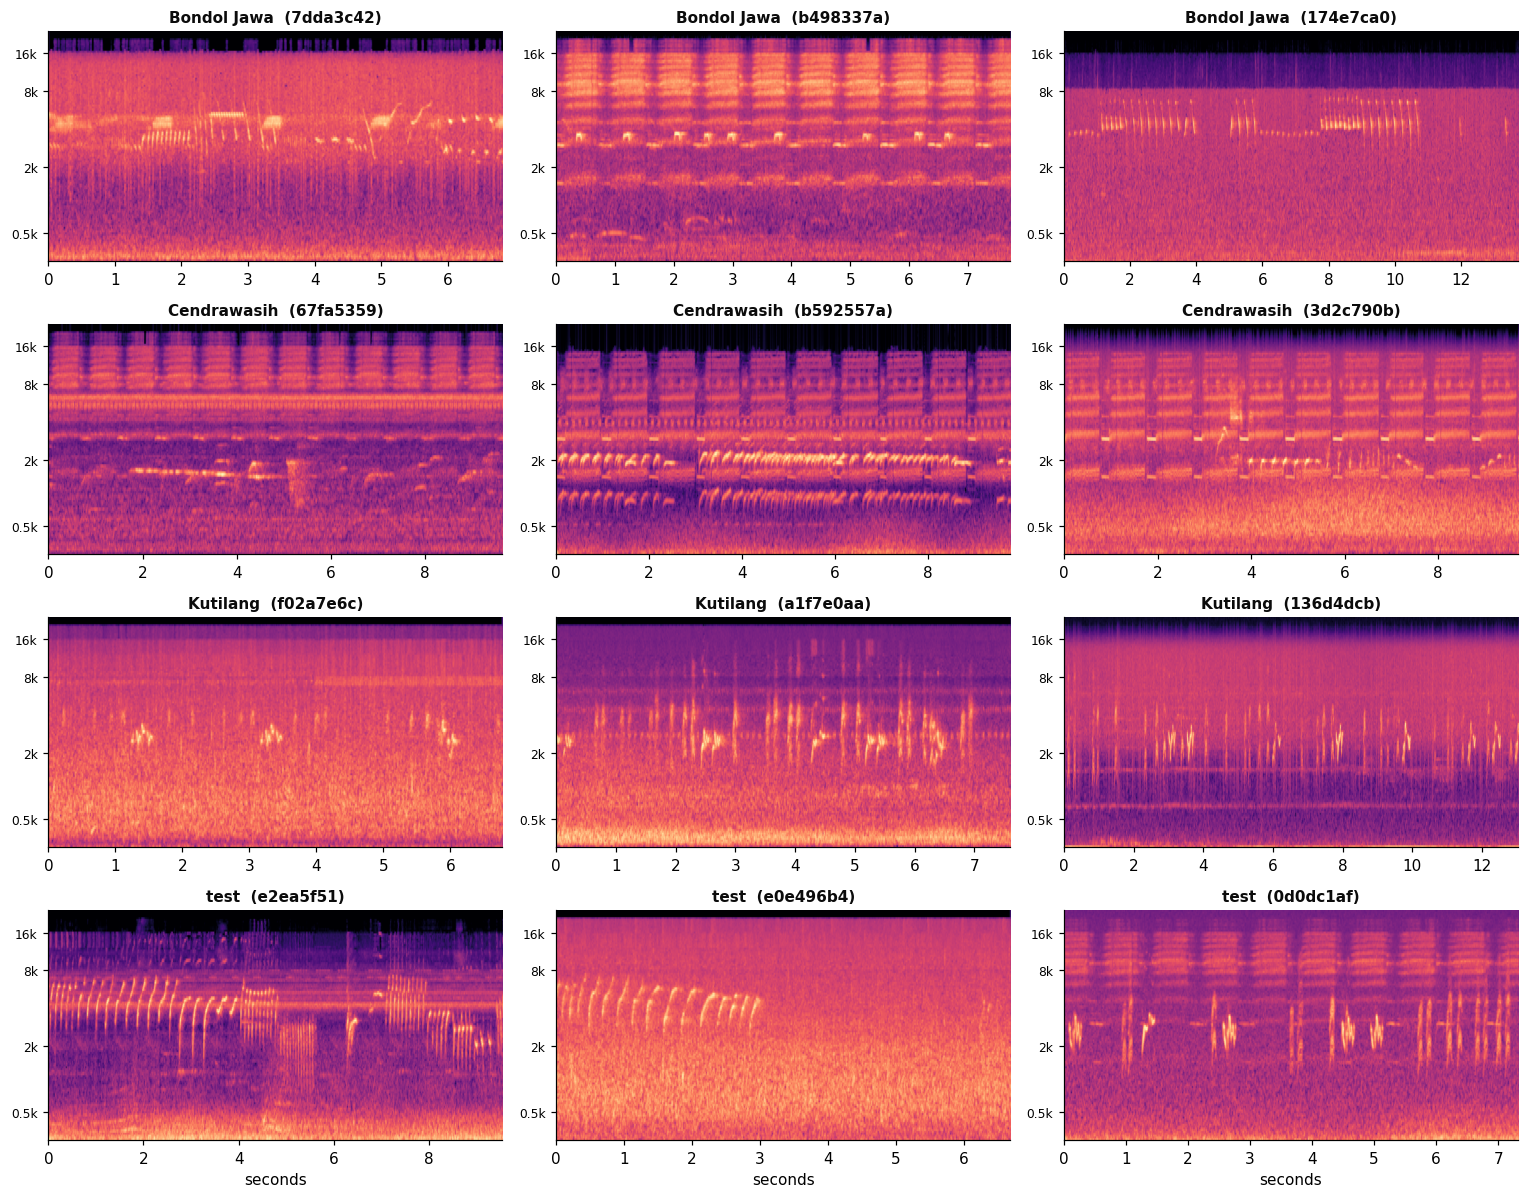

Bondol Jawa 7dda3c42


Cendrawasih 67fa5359


Kutilang f02a7e6c


test e2ea5f51


In [10]:
rng = np.random.default_rng(3)
picks = []
for c in CLASSES:
    gs = rng.permutation(tr[tr.label == c].source_group.unique())[:3]
    picks += [(c, rng.choice(tr[tr.source_group == g].file_id.values)) for g in gs]
picks += [("test", f) for f in rng.choice(st[~TR].file_id.values, 3, replace=False)]

def raw(split, fid):
    path = C.DATA_DIR / split / "audio" / f"{fid}.flac"
    x, sr = sf.read(str(path), dtype="float32", always_2d=True)
    return x.mean(1), sr

fig, axes = plt.subplots(4, 3, figsize=(14, 11))
for ax, (who, fid) in zip(axes.ravel(), picks):
    y, sr = raw("test" if who == "test" else "train", fid)
    M = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=512,
                                                           n_mels=128, fmax=sr / 2), ref=np.max)
    ax.imshow(M, origin="lower", aspect="auto", cmap="magma", vmin=-80, extent=[0, len(y) / sr, 0, 128])
    mel_ticks = librosa.hz_to_mel([500, 2000, 8000, 16000]) / librosa.hz_to_mel(sr / 2) * 128
    ax.set_yticks(mel_ticks, ["0.5k", "2k", "8k", "16k"], fontsize=8)
    ax.set_title(f"{who}  ({fid[:8]})", fontsize=10, color="#0b0b0b")
    ax.grid(False)
for ax in axes[-1]:
    ax.set_xlabel("seconds")
plt.tight_layout(); plt.show()

for who, fid in picks[::3]:
    y, sr = raw("test" if who == "test" else "train", fid)
    print(who, fid[:8]); display(Audio(y, rate=sr))

**What to check by ear and eye:** whether each species has a recognisable call shape, how much of each clip is only background, what kinds of noise appear (rain, insects, wind, voices), and whether the test clips contain calls that don't look like any of the three species.

## Summary: what EDA tells preprocessing

| Evidence | Decision in `02_preprocessing.ipynb` |
|---|---|
| Each group is one species; background alone predicts species at about 0.52 balanced accuracy | Group-held-out folds, PCEN, cross-group background mixing |
| Added noise (insect-like pulses, wind, hiss) is spread evenly across classes and test, with about 1/3 of clips pulsing | Not a shortcut, but the model must ignore it: noise mixing in training; check that crops aren't chasing pulses |
| No energy above 16 kHz | Resample to 32 kHz, `fmax` = 15 kHz |
| Cendrawasih is lower-pitched (0.5–2 kHz) | Keep `fmin` low (40 Hz), no aggressive high-pass |
| Loudness is equal across classes and test, no clipping (organiser peak-normalised to 0.98) | No repair needed; per-clip normalisation is a safe default |
| Cendrawasih is 4.5% of clips, lowest SNR | Class weights or a balanced sampler; watch Cendrawasih recall |
| Test is shifted (AUC about 0.77); about 17% of test is far from all training data | Treat validation scores as optimistic; build an explicit `Unknown` rejection step |
| Clips are 5–15 s and calls take up only part of each clip | 5 s windows, activity-weighted crops, sliding windows at test |